# 📏 베이스라인 평가 — 정확도의 함정 확인

- **목적**: 아무것도 학습하지 않는 Dummy 모델과 로지스틱 회귀(기본 / class_weight)로, 이후 모델이 넘어야 할 **기준선**을 정합니다.
- **선행**: `eda_and_split.ipynb`
- **산출물**: `reports/tables/baseline_val_metrics.csv`, `baseline_val_thresholds.csv`, `reports/figures/logistic_regression_simulation.png`
- **원칙**: Validation만 사용하며 Test 데이터는 사용하지 않습니다.

## 1. 환경 설정 및 데이터 로드

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

# 프로젝트 최상위 폴더 (이 노트북은 experiments 폴더에서 실행)
PROJECT_ROOT = Path.cwd().parent

# 공통 함수가 있는 src 폴더를 파이썬 검색 경로에 추가 (한글 폰트도 utils에서 설정됨)
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from utils import (
    load_and_preprocess_data,
    evaluate_fds_model,
    evaluate_thresholds,
    plot_and_save_simulation,
)

DATA_DIR = PROJECT_ROOT / "data" / "processed"
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures"
TABLE_DIR = PROJECT_ROOT / "reports" / "tables"          # 결과표(CSV) 저장 위치
TABLE_DIR.mkdir(parents=True, exist_ok=True)
RANDOM_STATE = 42

X_train, y_train, X_val, y_val = load_and_preprocess_data(DATA_DIR)
print(f"검증 사기 거래: {y_val.sum()}건 ({y_val.mean():.4%})")

[Data Loaded] Train: (198624, 30), Validation: (42561, 30)
검증 사기 거래: 73건 (0.1715%)


## 2. Baseline 1 — Dummy 모델 (정확도의 함정)

모든 거래를 "정상"으로 예측합니다. 정확도는 99.8%를 넘지만 사기는 한 건도 잡지 못합니다.
사기 확률은 모든 거래에 같은 값(학습 데이터의 사기 비율)을 주므로 PR-AUC는 무작위 수준(≈ 사기 비율)이 됩니다.

In [2]:
results = []

# 가장 많은 클래스(0: 정상)로만 예측하는 모델
dummy_model = DummyClassifier(strategy="most_frequent")
dummy_model.fit(X_train, y_train)

dummy_pred = dummy_model.predict(X_val)
# 모든 거래에 같은 사기 확률(학습 데이터 사기 비율)을 부여
dummy_prob = np.full(len(y_val), y_train.mean(), dtype=float)

results.append(evaluate_fds_model("Dummy Model (Most Frequent)", y_val, dummy_pred, dummy_prob))


================ [Dummy Model (Most Frequent)] 평가 결과 ================
1. Accuracy  (정확도) : 0.99828
2. PR-AUC    (평균정밀도): 0.00172 ★
3. Recall    (재현율)  : 0.00000
4. Precision (정밀도)  : 0.00000
5. F1-Score  (조화평균): 0.00000
----------------------------------------------------------
Confusion Matrix (혼동행렬):
[[42488     0]
 [   73     0]]
 - TN(정상 예측 성공): 42,488건 | FP(오탐 / 오인 신고): 0건 | FN(미탐 / 놓친 사기): 73건 | TP(사기 탐지 성공): 0건



## 3. Baseline 2 — 기본 로지스틱 회귀

클래스 가중치나 임계값 조정 없이 기본 설정(임계값 0.5)으로 학습한 선형 모델입니다.

In [3]:
lr_model = LogisticRegression(random_state=RANDOM_STATE, max_iter=1000, solver="lbfgs")
lr_model.fit(X_train, y_train)

lr_pred = lr_model.predict(X_val)                 # 기본 임계값 0.5 기준 예측
lr_prob = lr_model.predict_proba(X_val)[:, 1]     # 사기(1) 클래스 확률

results.append(evaluate_fds_model("Basic Logistic Regression", y_val, lr_pred, lr_prob))


================ [Basic Logistic Regression] 평가 결과 ================
1. Accuracy  (정확도) : 0.99901
2. PR-AUC    (평균정밀도): 0.71707 ★
3. Recall    (재현율)  : 0.50685
4. Precision (정밀도)  : 0.86047
5. F1-Score  (조화평균): 0.63793
----------------------------------------------------------
Confusion Matrix (혼동행렬):
[[42482     6]
 [   36    37]]
 - TN(정상 예측 성공): 42,482건 | FP(오탐 / 오인 신고): 6건 | FN(미탐 / 놓친 사기): 36건 | TP(사기 탐지 성공): 37건



## 4. Baseline 3 — 로지스틱 회귀 + class_weight='balanced'

사기 거래에 (정상 건수 / 사기 건수)만큼 큰 가중치를 주어, 모델이 사기를 놓칠 때 더 큰 벌점을 받도록 합니다.
- 예상: 임계값 0.5 기준으로 **Recall은 크게 오르고 Precision은 크게 떨어집니다.** 모델이 사기 확률을 전반적으로 높게 내놓기 때문입니다.
- PR-AUC는 확률의 **순위**만 보므로 크게 달라지지 않을 수 있습니다. 가중치는 "순위"보다 "어디서 자르느냐"에 주로 영향을 줍니다.

In [4]:
lr_bal_model = LogisticRegression(
    class_weight="balanced", random_state=RANDOM_STATE, max_iter=1000, solver="lbfgs"
)
lr_bal_model.fit(X_train, y_train)

lr_bal_pred = lr_bal_model.predict(X_val)                 # 기본 임계값 0.5 기준 예측
lr_bal_prob = lr_bal_model.predict_proba(X_val)[:, 1]     # 사기(1) 클래스 확률

results.append(evaluate_fds_model("Logistic Regression (class_weight)", y_val, lr_bal_pred, lr_bal_prob))


================ [Logistic Regression (class_weight)] 평가 결과 ================
1. Accuracy  (정확도) : 0.97209
2. PR-AUC    (평균정밀도): 0.71514 ★
3. Recall    (재현율)  : 0.89041
4. Precision (정밀도)  : 0.05221
5. F1-Score  (조화평균): 0.09863
----------------------------------------------------------
Confusion Matrix (혼동행렬):
[[41308  1180]
 [    8    65]]
 - TN(정상 예측 성공): 41,308건 | FP(오탐 / 오인 신고): 1,180건 | FN(미탐 / 놓친 사기): 8건 | TP(사기 탐지 성공): 65건



## 5. 로지스틱 회귀 임계값별 검토 건수 시뮬레이션 (기본 모델)

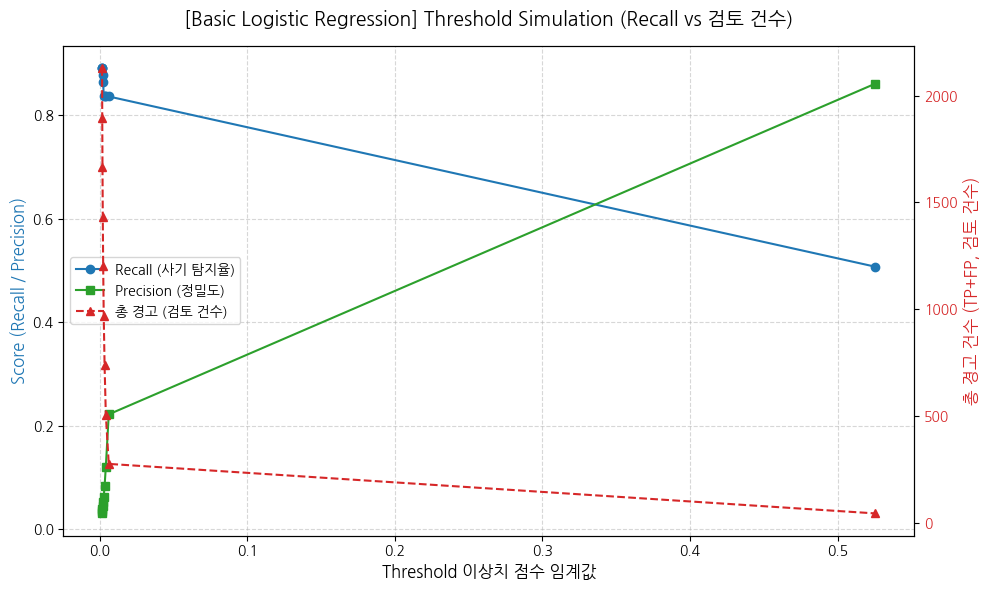

[저장 완료] 그래프 파일: /home/user1/study/credit-card-fds/reports/figures/logistic_regression_simulation.png


,Threshold,Recall,Precision,F1-Score,TP (사기 탐지),FP (오탐/검토 대상),FN (놓친 사기),Total Flagged (총 경고),Model,Split
0,0.001516,0.890411,0.030531,0.059037,65,2064,8,2129,LogisticRegression,validation
1,0.001633,0.890411,0.034265,0.065990,65,1832,8,1897,LogisticRegression,validation
2,0.001799,0.890411,0.039039,0.074799,65,1600,8,1665,LogisticRegression,validation
3,0.001998,0.876712,0.044662,0.084993,64,1369,9,1433,LogisticRegression,validation
4,0.002261,0.863014,0.052413,0.098824,63,1139,10,1202,LogisticRegression,validation
5,0.002638,0.835616,0.062887,0.116970,61,909,12,970,LogisticRegression,validation
6,0.003208,0.835616,0.082656,0.150432,61,677,12,738,LogisticRegression,validation
7,0.004059,0.835616,0.120553,0.210708,61,445,12,506,LogisticRegression,validation
8,0.006050,0.835616,0.221818,0.350575,61,214,12,275,LogisticRegression,validation
9,0.525665,0.506849,0.860465,0.637931,37,6,36,43,LogisticRegression,validation


In [5]:
# 임계값 후보를 지정하지 않으면 확률 상위 0.1~5% 구간에서 10개를 자동 생성
lr_thresholds = evaluate_thresholds(y_val, lr_prob)
lr_thresholds["Model"] = "LogisticRegression"
lr_thresholds["Split"] = "validation"

# 그래프의 오른쪽 축은 총 경고 건수(TP + FP = 상담원 검토 건수)
plot_and_save_simulation(
    lr_thresholds,
    model_name="Basic Logistic Regression",
    filename="logistic_regression_simulation.png",
    figures_dir=FIGURE_DIR,
)
display(lr_thresholds)

## 6. 결과 저장 및 요약

In [6]:
results_df = pd.DataFrame(results)
results_df["Split"] = "validation"
results_df["Threshold"] = 0.5

results_df.to_csv(TABLE_DIR / "baseline_val_metrics.csv", index=False, encoding="utf-8-sig")
lr_thresholds.to_csv(TABLE_DIR / "baseline_val_thresholds.csv", index=False, encoding="utf-8-sig")
print(f"[저장] {TABLE_DIR / 'baseline_val_metrics.csv'}")
print(f"[저장] {TABLE_DIR / 'baseline_val_thresholds.csv'}")

display(results_df[["Model", "Accuracy", "PR_AUC", "Recall", "Precision", "TP", "FP", "FN"]].round(4))

[저장] /home/user1/study/credit-card-fds/reports/tables/baseline_val_metrics.csv
[저장] /home/user1/study/credit-card-fds/reports/tables/baseline_val_thresholds.csv


,Model,Accuracy,PR_AUC,Recall,Precision,TP,FP,FN
0,Dummy Model (Most Frequent),0.9983,0.0017,0.0000,0.0000,0,0,73
1,Basic Logistic Regression,0.9990,0.7171,0.5068,0.8605,37,6,36
2,Logistic Regression (class_weight),0.9721,0.7151,0.8904,0.0522,65,1180,8


### 결과 해석

| 모델 | Accuracy | PR-AUC | Recall | Precision | 경고 건수 |
|---|---|---|---|---|---|
| Dummy (전부 정상) | 0.998 | 0.002 | 0.00 | – | 0 |
| 기본 로지스틱 회귀 | 0.999 | 0.717 | 0.51 | 0.86 | 43 |
| 로지스틱 회귀 + class_weight | **0.972** | 0.715 | **0.89** | **0.05** | **1,245** |

- **정확도의 함정**: Dummy는 사기를 하나도 못 잡는데 정확도가 0.998입니다. 정확도로는 모델을 비교할 수 없습니다.
- **class_weight의 효과**: Recall은 0.51 → 0.89로 올랐지만 경고가 43건 → 1,245건으로 늘었습니다. 정확도는 오히려 내려갔습니다.
- **PR-AUC는 거의 같습니다**(0.717 vs 0.715). 가중치는 확률의 **순위**는 거의 바꾸지 않고, 확률을 전체적으로 끌어올려 **임계값 0.5의 위치**만 바꾼 것입니다. → 불균형 문제는 가중치만이 아니라 **임계값 조정**으로도 다룰 수 있다는 뜻이고, 이후 노트북이 임계값 시뮬레이션을 하는 이유입니다.